<xarray.Dataset>
Dimensions:      (TIME: 336, bnds: 2, LONN719_721: 401, LAT: 421)
Coordinates:
  * TIME         (TIME) datetime64[ns] 1993-01-16 ... 2020-12-16
  * LONN719_721  (LONN719_721) float64 20.0 20.25 20.5 ... 119.5 119.8 120.0
  * LAT          (LAT) float64 -75.0 -74.75 -74.5 -74.25 ... 29.5 29.75 30.0
Dimensions without coordinates: bnds
Data variables:
    TIME_bnds    (TIME, bnds) datetime64[ns] ...
    U            (TIME, LAT, LONN719_721) float32 ...
    V            (TIME, LAT, LONN719_721) float32 ...
Attributes:
    CDI:          Climate Data Interface version ?? (http://mpimet.mpg.de/cdi)
    Conventions:  CF-1.0
    history:      Tue Oct 17 14:52:49 2023: cdo monavg IO_OSCAR.nc IO_OSCAR_m...
    frequency:    mon
    CDO:          Climate Data Operators version 1.9.3 (http://mpimet.mpg.de/...


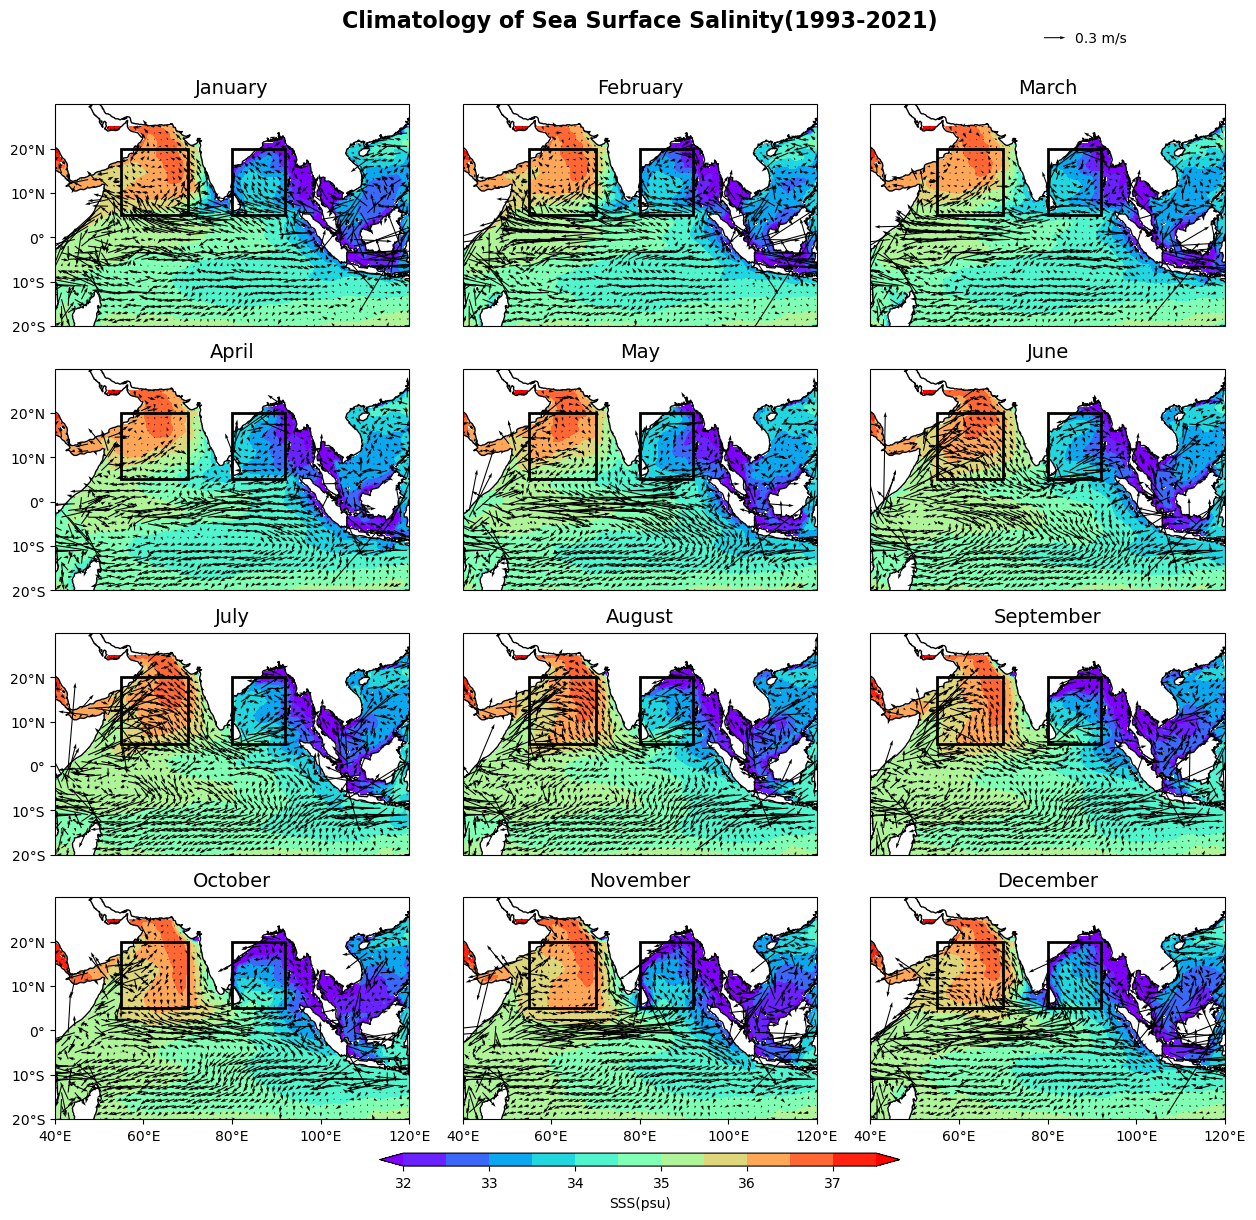

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import calendar
import cartopy.mpl.ticker as cticker
import calendar
from matplotlib.patches import Rectangle
from matplotlib.ticker import MultipleLocator
ds = xr.open_dataset('salinity2.nc')
#print(ds)
#get data sliced for the particular year
ds = ds.sel(lat=slice(-20,25),lon=slice(40,120))
sal=ds['sosaline'].values
#climatology
#climatology= ds.groupby('time_counter.month').mean(dim='time_counter')
#print(climatology)
clevels=np.arange(32,38,0.5)
dss=xr.open_dataset('current.nc')
print(dss)
dss =dss.sel( TIME= slice('1993','2021'),LAT=slice(-20,25),LONN719_721=slice(40,120))
dss_cur1 = dss['U']
dss_cur2 =dss['V']
lon_cur =dss['LONN719_721'].values
#print(lon_cur[::10].shape)
lat_cur =dss['LAT'].values
#print(lat_cur[::10].shape)
t = dss['TIME'].values  
u_clim = dss_cur1.groupby('TIME.month').mean(dim='TIME', skipna=True)
#print(u_clim[::10].shape)
v_clim= dss_cur2.groupby('TIME.month').mean(dim='TIME', skipna=True)
#print(v_clim[::10].shape)
#clevels=np.arange(24,30.5,0.5)
quiver_scale = 2.5
quiver_plots = []

fig,axs = plt.subplots(nrows = 4, ncols = 3, subplot_kw = {'projection':ccrs.PlateCarree()}, figsize = (13,13))
plt.subplots_adjust(left=0.05, right=0.95, bottom=0.113, top=0.9, wspace=0.15, hspace=0.15)
axs = axs.flatten()
for j in range(12):
    cf = axs[j].contourf(ds['lon'], ds['lat'],ds['sosaline'].values[j],cmap='rainbow',levels=clevels,extend='both', transform=ccrs.PlateCarree())
    #lon_slice=lon_cur[::10]
    #lat_slice=lat_cur[::10]
    cq = axs[j].quiver(lon_cur[::6], lat_cur[::6], u_clim[j, ::6, ::6],v_clim[j, ::6, ::6], scale = quiver_scale*2, color='black', width=0.003, headwidth=3)
    axs[j].coastlines()
for j in range(12):    
      if j>=9:
         lon_range = np.arange(np.floor(ds['lon'].min()), np.ceil(ds['lon'].max()) + 1,20)
         axs[j].set_xticks(lon_range, crs=ccrs.PlateCarree())
         lon_formatter = cticker.LongitudeFormatter()
         axs[j].xaxis.set_major_formatter(lon_formatter)
    
        
       # Define the yticks for latitude
      if j%3==0:
          lat_range = np.arange(np.floor(ds['lat'].min()), np.ceil(ds['lat'].max())+1,10)
          axs[j].set_yticks(lat_range, crs=ccrs.PlateCarree())
          lat_formatter = cticker.LatitudeFormatter()
          axs[j].yaxis.set_major_formatter(lat_formatter)
    
       #add month name to the plot
      month_name=calendar.month_name[j+1]
      axs[j].text(0.5,1.05,month_name,ha='center',transform=axs[j].transAxes,fontsize=14)
plt.suptitle('Climatology of Sea Surface Salinity(1993-2021)',fontsize=16,fontweight='bold',y=0.97)
axs[2].quiverkey(cq, X=0.55, Y=4.88, U=0.3, label=f'{0.3} m/s', labelpos='E',coordinates='axes')

for i in range(len(axs)):

    axs[i].set_xlim(40,120)
    axs[i].set_ylim(-20,30)
box1=[55,70,5,20]
box2=[80,92,5,20]
for i in range(12):
    axs[i].add_patch(Rectangle((box1[0],box1[2]),box1[1]-box1[0],box1[3]-box1[2],fill=None,edgecolor='black',linewidth=2))
    axs[i].add_patch(Rectangle((box2[0],box2[2]),box2[1]-box2[0],box2[3]-box2[2],fill=None,edgecolor='black',linewidth=2))

# Define the subplot axis for the colorbar
cbar_ax = fig.add_axes([0.3, 0.08, 0.4, 0.01])
cbar = fig.colorbar(cf, cax=cbar_ax, orientation='horizontal', label='SSS(psu)')
cbar.ax.xaxis.set_label_coords(0.5, -2.3)
plt.savefig(r'C:\Users\henna\Desktop\plots\scurrent.eps',format='eps',dpi=300)
plt.show()


    

In [2]:
ds

<xarray.Dataset>
Dimensions:            (time_counter: 12, bnds: 2, lon: 401, lat: 241)
Coordinates:
  * time_counter       (time_counter) datetime64[ns] 2022-01-16T12:00:00 ... ...
  * lon                (lon) float64 30.0 30.25 30.5 30.75 ... 129.5 129.8 130.0
  * lat                (lat) float64 -30.0 -29.75 -29.5 ... 29.5 29.75 30.0
Dimensions without coordinates: bnds
Data variables:
    time_counter_bnds  (time_counter, bnds) datetime64[ns] ...
    sosaline           (time_counter, lat, lon) float32 ...
Attributes:
    CDI:          Climate Data Interface version 2.0.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.4
    source:       ORAS5 - backward extension (ECMWF)
    institution:  European Centre for Medium-Range Weather Forecasts (ECMWF) ...
    NCO:          netCDF Operators version 4.9.2 (Homepage = http://nco.sf.ne...
    title:        Monthly mean 2D Sea Surface fields
    reference:    https://www.ecmwf.int/en/research/climate-reanalysis/ocean-...
    history:      Fri Feb 10 16:20:09 2023: cdo sellonlatbox,30,130,-30,30 CL...
    CDO:          Climate Data Operators version 2.0.4 (https://mpimet.mpg.de...

In [3]:
dss

NameError: name 'dss' is not defined